<a href="https://colab.research.google.com/github/LikithaC17/GenAI-Training/blob/main/Diabetes_DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DAY 2- 2.2

In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score,confusion_matrix,classification_report, precision_score,recall_score

In [ ]:
df = pd.read_excel("/content/diabetesxl.xlsx")
df.head(7)

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive
5,5,116,74,0,0,25.6,0.201,30,tested_negative
6,3,78,50,32,88,31.0,0.248,26,tested_positive


In [ ]:
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
df.dropna()
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
df.dropna(inplace= True)
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Number of duplicate rows:",df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df.drop_duplicates(inplace=True)
print("Number of duplicate rows:",df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
x= df[["age","mass", "insu" ,"plas"]]
y= df["class"]


In [ ]:
x= df[["age","mass","insu", "plas"]]
y = df["class"]
print("Feature shape:",x.shape, "Target shape:",y.shape)

Feature shape: (768, 4) Target shape: (768,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)
print("Records for training:", len(x_train))
print("Records for testing:", len(x_test))

Records for training: 614
Records for testing: 154


In [ ]:
Deci =  DecisionTreeClassifier()

In [ ]:
Deci.fit(x_train, y_train)

DecisionTreeClassifier()

In [ ]:
y_predict = Deci.predict(x_test)
result= pd.DataFrame({
    "Actual": y_test,
    "Predicated" : y_predict
})
result.head(10)


,Actual,Predicated
668,tested_negative,tested_positive
324,tested_negative,tested_positive
624,tested_negative,tested_negative
690,tested_negative,tested_negative
473,tested_negative,tested_negative
204,tested_negative,tested_positive
97,tested_negative,tested_negative
336,tested_negative,tested_positive
568,tested_negative,tested_positive
148,tested_negative,tested_positive


In [ ]:
age = int(input("Enter Age: "))
mass= int(input("Enter mass: "))
insulin= int(input("Enter insulin: "))
plasma= int(input("Enter plasma level: "))
pred=Deci.predict([[age,mass,insulin,plasma]])

if pred == 'tested_positive':
  print("Please consult a Doctor")
else:
  print("Eat Kaju moreee")

Enter Age: 21
Enter mass: 31
Enter insulin: 100
Enter plasma level: 150
Please consult a Doctor


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
print("Accuracy:", accuracy_score(y_test,y_predict))
print("Precision:", precision_score(y_test,y_predict,pos_label="tested_positive"))
print("Recall:", recall_score(y_test,y_predict,pos_label="tested_positive"))
print("F1 Score:", f1_score(y_test,y_predict,pos_label="tested_positive"))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_predict))


Accuracy: 0.6688311688311688
Precision: 0.532258064516129
Recall: 0.6
F1 Score: 0.5641025641025641
Confusion Matrix:
 [[70 29]
 [22 33]]


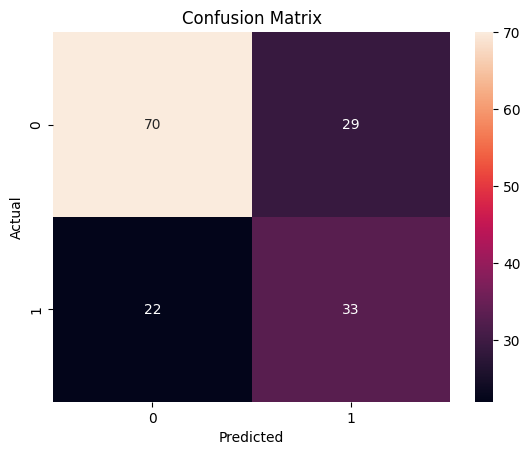

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test,y_predict)
sns.heatmap(cm,annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.tree import plot_tree

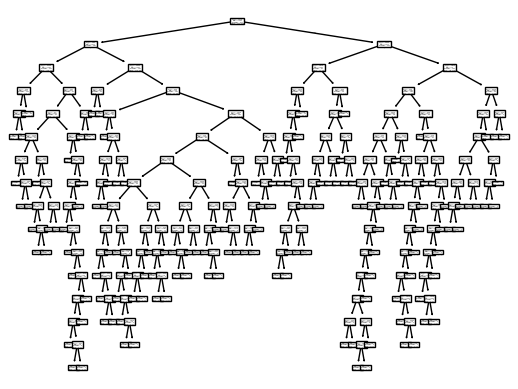

In [ ]:
plot_tree(Deci)
plt.show()

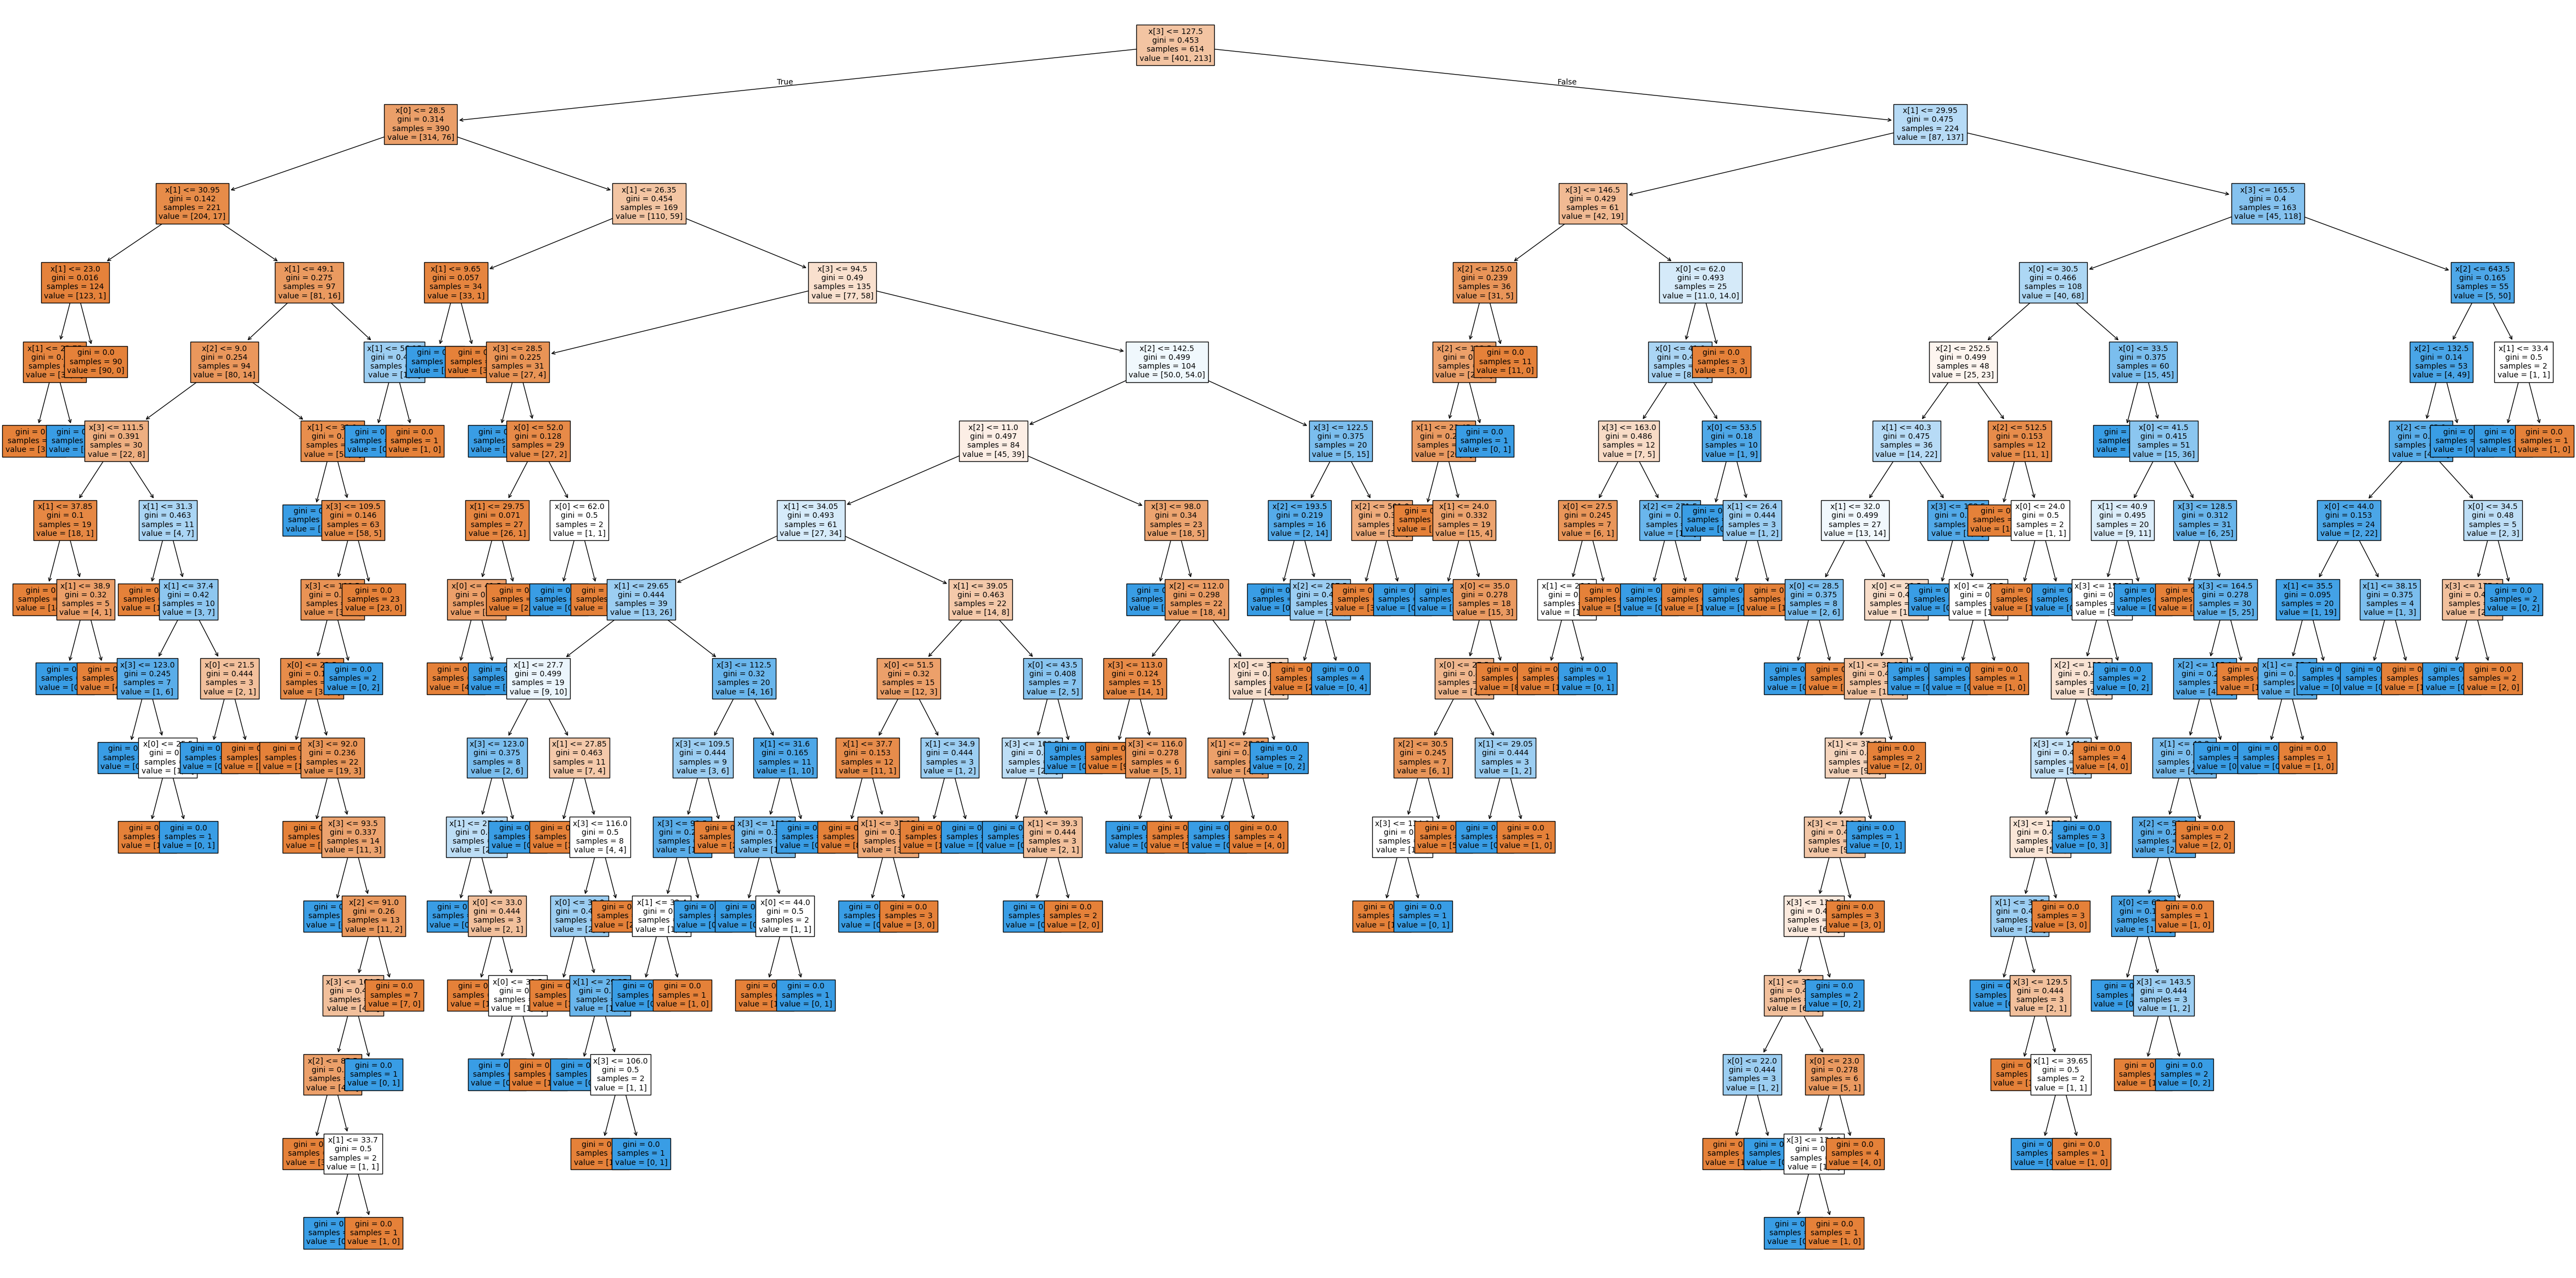

In [ ]:
plt.figure(figsize = (60,30))
plot_tree(Deci, fontsize =10, filled =True)
plt.savefig("DecisionTree.pdf")